In [1]:
!pip install ipympl
from google.colab import output
output.enable_custom_widget_manager()
%matplotlib widget

<>:152: SyntaxWarning: invalid escape sequence '\o'
<>:157: SyntaxWarning: invalid escape sequence '\o'
<>:152: SyntaxWarning: invalid escape sequence '\o'
<>:157: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipykernel_1997/363180169.py:152: SyntaxWarning: invalid escape sequence '\o'
  self.ax_mag.set_title('Magnitud $|H(e^{j\omega})|$')
/tmp/ipykernel_1997/363180169.py:157: SyntaxWarning: invalid escape sequence '\o'
  self.ax_fase.set_xlabel('$\omega$ (rad/muestra)')


HTML(value='<b>Forma factorizada:</b> H(z) = 1.0 * [1] / [1]<br><b>Numerador (b):</b> [1.]<br><b>Denominador (…

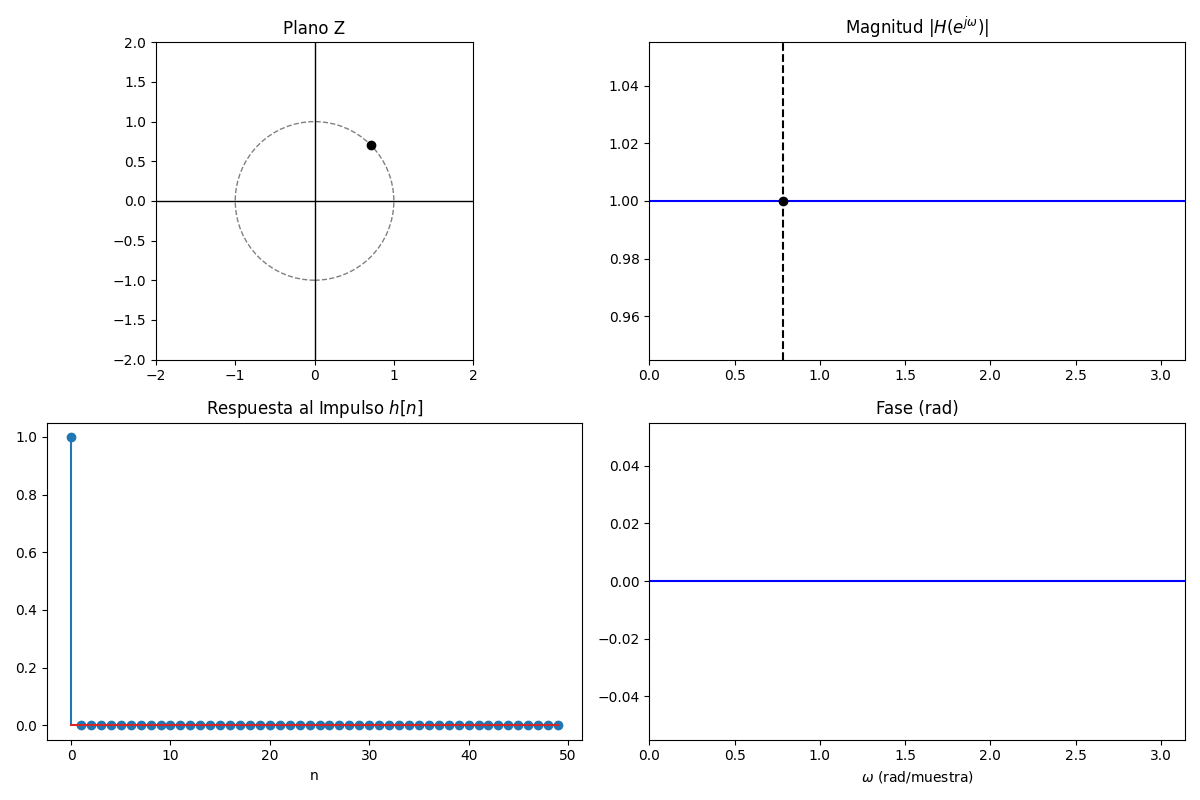

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import scipy.signal as sig
import ipywidgets as widgets
from IPython.display import display, HTML

class FiltroInteractivoZ:
    def __init__(self):
        self.polos = []
        self.ceros = []
        self.K = 1.0
        self.omega_val = np.pi / 4
        self.modo = 'Añadir Polo'
        self.arrastrando = None

        # Configuración de la figura
        self.fig = plt.figure(figsize=(12, 8))
        self.fig.canvas.header_visible = False
        self.ax_z = plt.subplot(2, 2, 1)
        self.ax_mag = plt.subplot(2, 2, 2)
        self.ax_fase = plt.subplot(2, 2, 4)
        self.ax_imp = plt.subplot(2, 2, 3)

        # Interfaz de widgets
        self.w_modo = widgets.RadioButtons(
            options=['Añadir Polo', 'Añadir Cero', 'Mover', 'Eliminar'],
            description='Acción:',
            layout=widgets.Layout(width='max-content')
        )
        self.w_omega = widgets.FloatSlider(
            value=self.omega_val, min=0, max=np.pi, step=0.05,
            description='Frec. ω:', continuous_update=True
        )
        self.w_info = widgets.HTML(value="<b>Función de Transferencia H(z)</b>")

        self.w_modo.observe(self.cambiar_modo, names='value')
        self.w_omega.observe(self.cambiar_omega, names='value')

        # Eventos de ratón
        self.fig.canvas.mpl_connect('button_press_event', self.on_press)
        self.fig.canvas.mpl_connect('motion_notify_event', self.on_motion)
        self.fig.canvas.mpl_connect('button_release_event', self.on_release)

        self.actualizar_graficas()
        display(widgets.HBox([self.w_modo, self.w_omega]), self.w_info)

    def cambiar_modo(self, change):
        self.modo = change.new

    def cambiar_omega(self, change):
        self.omega_val = change.new
        self.actualizar_graficas()

    def _obtener_raiz_cercana(self, z_click, umbral=0.1):
        min_dist = umbral
        objetivo, tipo = None, None

        for p in self.polos:
            if np.abs(p - z_click) < min_dist:
                min_dist = np.abs(p - z_click)
                objetivo, tipo = p, 'polo'
        for c in self.ceros:
            if np.abs(c - z_click) < min_dist:
                min_dist = np.abs(c - z_click)
                objetivo, tipo = c, 'cero'
        return objetivo, tipo

    def on_press(self, event):
        if event.inaxes != self.ax_z: return
        z_click = event.xdata + 1j * event.ydata

        if self.modo == 'Añadir Polo':
            self.polos.append(z_click)
            if abs(z_click.imag) > 0.05: # Añadir conjugado para coeficientes reales
                self.polos.append(np.conj(z_click))
        elif self.modo == 'Añadir Cero':
            self.ceros.append(z_click)
            if abs(z_click.imag) > 0.05:
                self.ceros.append(np.conj(z_click))
        elif self.modo == 'Eliminar':
            obj, tipo = self._obtener_raiz_cercana(z_click)
            if tipo == 'polo':
                self.polos = [p for p in self.polos if p != obj and p != np.conj(obj)]
            elif tipo == 'cero':
                self.ceros = [c for c in self.ceros if c != obj and c != np.conj(obj)]
        elif self.modo == 'Mover':
            self.arrastrando, self.tipo_arrastre = self._obtener_raiz_cercana(z_click)

        self.actualizar_graficas()

    def on_motion(self, event):
        if self.arrastrando is None or event.inaxes != self.ax_z: return
        z_nuevo = event.xdata + 1j * event.ydata

        # Eliminar el antiguo (y su conjugado) y añadir el nuevo en la lista
        if self.tipo_arrastre == 'polo':
            self.polos = [p for p in self.polos if p != self.arrastrando and p != np.conj(self.arrastrando)]
            self.polos.append(z_nuevo)
            if abs(z_nuevo.imag) > 0.05: self.polos.append(np.conj(z_nuevo))
        else:
            self.ceros = [c for c in self.ceros if c != self.arrastrando and c != np.conj(self.arrastrando)]
            self.ceros.append(z_nuevo)
            if abs(z_nuevo.imag) > 0.05: self.ceros.append(np.conj(z_nuevo))

        self.arrastrando = z_nuevo
        self.actualizar_graficas()

    def on_release(self, event):
        self.arrastrando = None

    def actualizar_graficas(self):
        # Limpiar ejes
        for ax in [self.ax_z, self.ax_mag, self.ax_fase, self.ax_imp]: ax.clear()

        # 1. Plano Z interactivo
        circulo = Circle((0,0), radius=1, fill=False, color='gray', linestyle='--')
        self.ax_z.add_patch(circulo)
        self.ax_z.axhline(0, color='black', lw=1)
        self.ax_z.axvline(0, color='black', lw=1)

        if self.polos:
            self.ax_z.plot(np.real(self.polos), np.imag(self.polos), 'x', markersize=10, color='red', label='Polos')
        if self.ceros:
            self.ax_z.plot(np.real(self.ceros), np.imag(self.ceros), 'o', markersize=10, color='blue', mfc='none', label='Ceros')

        # Exploración geométrica
        z_w = np.exp(1j * self.omega_val)
        self.ax_z.plot(np.real(z_w), np.imag(z_w), 'ko')
        for p in self.polos: self.ax_z.plot([np.real(p), np.real(z_w)], [np.imag(p), np.imag(z_w)], 'r:', alpha=0.5)
        for c in self.ceros: self.ax_z.plot([np.real(c), np.real(z_w)], [np.imag(c), np.imag(z_w)], 'b:', alpha=0.5)

        self.ax_z.set_xlim([-2, 2]); self.ax_z.set_ylim([-2, 2])
        self.ax_z.set_title('Plano Z')
        self.ax_z.set_aspect('equal')

        # Obtener H(z)
        num, den = sig.zpk2tf(self.ceros, self.polos, self.K)
        num, den = np.real(num), np.real(den)

        # Formatear texto H(z)
        str_num = " * ".join([f"(z - {c:.2f})" for c in self.ceros]) if self.ceros else "1"
        str_den = " * ".join([f"(z - {p:.2f})" for p in self.polos]) if self.polos else "1"
        self.w_info.value = f"<b>Forma factorizada:</b> H(z) = {self.K} * [{str_num}] / [{str_den}]<br>" \
                            f"<b>Numerador (b):</b> {np.round(num, 3)}<br><b>Denominador (a):</b> {np.round(den, 3)}"

        # 2. Respuesta en Frecuencia (Magnitud y Fase)
        w, h = sig.freqz(num, den, worN=512, include_nyquist=True)
        self.ax_mag.plot(w, np.abs(h), 'b')
        self.ax_mag.axvline(self.omega_val, color='k', linestyle='--')
        self.ax_mag.plot(self.omega_val, np.interp(self.omega_val, w, np.abs(h)), 'ko')
        self.ax_mag.set_title('Magnitud $|H(e^{j\omega})|$')
        self.ax_mag.set_xlim([0, np.pi])

        self.ax_fase.plot(w, np.angle(h), 'b')
        self.ax_fase.set_title('Fase (rad)')
        self.ax_fase.set_xlabel('$\omega$ (rad/muestra)')
        self.ax_fase.set_xlim([0, np.pi])

        # 3. Respuesta al Impulso (50 muestras)
        n = np.arange(50)
        impulso = sig.unit_impulse(50)
        # Manejo de estabilidad
        inestable = any(np.abs(p) >= 1.0 for p in self.polos)
        if not inestable:
            h_n = sig.lfilter(num, den, impulso)
            self.ax_imp.stem(n, h_n)
        else:
            self.ax_imp.text(0.5, 0.5, "SISTEMA INESTABLE\nPolos fuera o sobre el círculo",
                             ha='center', va='center', color='red', transform=self.ax_imp.transAxes)
        self.ax_imp.set_title('Respuesta al Impulso $h[n]$')
        self.ax_imp.set_xlabel('n')

        self.fig.tight_layout()
        self.fig.canvas.draw_idle()

# Ejecutar la aplicación
app = FiltroInteractivoZ()